<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook guide](README.md)

# When is a 10 km map ruler really 10 km?

A GIS export says two points are **10,000 metres apart in Web Mercator**.
Can we use that number as their distance on Earth? Follow an identical map
ruler from the equator toward the Arctic, recover its endpoints in longitude
and latitude, and ask the real **vgi-proj** worker for the WGS84 geodesic.
Then try a local UTM projection on those same endpoints.

These are **synthetic, deterministic endpoint pairs**, not surveyed routes.
The reference is shortest ellipsoidal distance, without terrain, elevation or
road routing. All projection and geodesic calculations run through Haybarn / VGI;
Python draws the returned results.

## Set the ruler and the latitude to inspect

Edit a value, then restart the kernel and **Run All**. Keep the map ruler fixed
for the final experiment: move the focus from **45°N to 60°N** and predict what
happens to its ground distance. The background sweep covers 0–75°N in 1° steps.
All segments are centred at **longitude −123°**, UTM zone 10N's central meridian.
There is no observation date or external data fetch for these local calculations.

In [1]:
FOCUS_LATITUDE_DEG = 45.0  # degrees north; finite number in [0, 75]; experiment: 60.0
MAP_LENGTH_M = 10000.0  # Web Mercator grid metres; finite number in [100, 50000]

In [2]:
import math
import os
import sys
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = Path.cwd() if (Path.cwd() / "notebook_support.py").is_file() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NOTEBOOK_DIR))

from notebook_support import (  # noqa: E402 — helper is a notebook companion
    GEODESIC,
    INK,
    MERCATOR,
    MUTED,
    UTM,
    chart,
    prose,
    set_theme,
)

for name, value, low, high in [
    ("FOCUS_LATITUDE_DEG", FOCUS_LATITUDE_DEG, 0, 75),
    ("MAP_LENGTH_M", MAP_LENGTH_M, 100, 50000),
]:
    if (
        isinstance(value, bool)
        or not isinstance(value, (int, float))
        or not math.isfinite(value)
        or not low <= value <= high
    ):
        raise ValueError(f"{name} must be a finite number in [{low}, {high}].")
# JupySQL's visible capture cells assign these DataFrames.
distance_frame = pd.DataFrame()
scale_frame = pd.DataFrame()
projection_frame = pd.DataFrame()
validation = pd.DataFrame()
set_theme()
con = haybarn.connect(config={"TimeZone": "UTC"})
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-proj/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-proj/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-proj-portable-ksu0xiwk/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-proj-portable-ksu0xiwk/notebooks/pyproject.toml.

## Connect and establish the coordinate contract

The literal `uvx` launch below installs GitHub release **v0.4.0** with
**pyproj 3.8.0** and **VGI Python SDK 0.51.0**. Its wheel bundles PROJ and its data.
No local worker checkout is needed; `uv` and Git must be on PATH. The notebook
has its own locked, published Haybarn **2.0.0rc11** environment.

The worker always takes **(longitude, latitude)** for geographic coordinates,
even where a CRS's native axis order differs. Projected coordinates are
**(x/easting, y/northing)**. Query the units first: a column called “metres”
tells us the coordinate unit, not whether Euclidean distance preserves ground length.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'proj' (TYPE vgi, LOCATION 'uvx --python 3.13 --with pyproj==3.8.0 --with vgi-python==0.51.0 --from git+https://github.com/Query-farm/vgi-proj@v0.4.0 vgi-proj-worker');
SELECT extension_name, extension_version, loaded
FROM duckdb_extensions() WHERE extension_name = 'vgi';

,extension_name,extension_version,loaded
0,vgi,e75482339d,True


In [4]:
%%sql
SELECT crs, proj.main.crs_name(crs) AS name, proj.main.crs_units(crs) AS coordinate_unit,
       axis_contract
FROM (VALUES
    ('EPSG:4326', 'longitude, latitude'),
    ('EPSG:3857', 'x, y'),
    ('EPSG:32610', 'easting, northing')
) t(crs, axis_contract);

,crs,name,coordinate_unit,axis_contract
0,EPSG:4326,WGS 84,degree,"longitude, latitude"
1,EPSG:3857,WGS 84 / Pseudo-Mercator,metre,"x, y"
2,EPSG:32610,WGS 84 / UTM zone 10N,metre,"easting, northing"


In [5]:
prose(
    f"**Local computational run.** Focus **{FOCUS_LATITUDE_DEG:g}°N**; "
    f"Web Mercator ruler **{MAP_LENGTH_M:,.0f} m**. Haybarn `{haybarn.__version__}`. "
    "The visible launch pins worker release `v0.4.0`, VGI SDK `0.51.0`, and pyproj `3.8.0` with bundled PROJ. "
    "No surveyed coordinates, private data or API responses are used."
)

**Local computational run.** Focus **45°N**; Web Mercator ruler **10,000 m**. Haybarn `2.0.0rc11`. The visible launch pins worker release `v0.4.0`, VGI SDK `0.51.0`, and pyproj `3.8.0` with bundled PROJ. No surveyed coordinates, private data or API responses are used.

## Give every latitude the same map ruler

SQL projects each synthetic midpoint to EPSG:3857, moves half a ruler west and
east in **map metres**, then inverse-projects the endpoints. The worker measures
the shortest **WGS84 ellipsoidal geodesic** between them. We materialize the
results once so charting does not repeat worker calls.

Both endpoints have the same latitude. Their shortest geodesic need not follow
that constant-latitude parallel. “Ground” below is shorthand for this ellipsoidal
endpoint distance, not the length of a road or a terrain-following path.

In [6]:
%%sql
CREATE OR REPLACE TABLE settings AS
SELECT {{ FOCUS_LATITUDE_DEG }}::DOUBLE AS focus_latitude_deg,
       {{ MAP_LENGTH_M }}::DOUBLE AS map_length_m,
       -123.0::DOUBLE AS midpoint_longitude_deg;
CREATE OR REPLACE TABLE latitude_grid AS
SELECT latitude_deg::DOUBLE AS latitude_deg FROM range(0, 76) t(latitude_deg)
UNION
SELECT focus_latitude_deg FROM settings;
CREATE OR REPLACE TABLE map_midpoints AS
SELECT g.latitude_deg, s.*,
       proj.main.to_webmercator(midpoint_longitude_deg, latitude_deg) AS centre
FROM latitude_grid g CROSS JOIN settings s;
CREATE OR REPLACE TABLE endpoints AS
SELECT *, centre.x - map_length_m / 2 AS west_x_m,
          centre.x + map_length_m / 2 AS east_x_m,
          proj.main.from_webmercator(centre.x - map_length_m / 2, centre.y) AS west,
          proj.main.from_webmercator(centre.x + map_length_m / 2, centre.y) AS east
FROM map_midpoints;
CREATE OR REPLACE TABLE distances AS
SELECT *,
       proj.main.geodesic_distance(west.lon, west.lat, east.lon, east.lat) AS geodesic_m,
       east_x_m - west_x_m AS webmercator_m,
       proj.main.geodesic_bearing(west.lon, west.lat, east.lon, east.lat) AS initial_bearing_deg
FROM endpoints;
SELECT COUNT(*) AS endpoint_pairs,
       COUNT(*) FILTER (WHERE west IS NULL OR east IS NULL OR geodesic_m IS NULL) AS missing_results,
       MIN(latitude_deg) AS first_latitude_deg, MAX(latitude_deg) AS last_latitude_deg,
       MIN(webmercator_m) AS shortest_map_ruler_m, MAX(webmercator_m) AS longest_map_ruler_m
FROM distances;

,endpoint_pairs,missing_results,first_latitude_deg,last_latitude_deg,shortest_map_ruler_m,longest_map_ruler_m
0,76,0,0.0,75.0,10000.0,10000.0


In [7]:
%%sql
SELECT latitude_deg, ROUND(west.lon, 6) AS west_longitude_deg,
       ROUND(east.lon, 6) AS east_longitude_deg,
       ROUND(webmercator_m, 2) AS map_metres,
       ROUND(geodesic_m, 2) AS geodesic_metres,
       ROUND(webmercator_m / geodesic_m, 4) AS map_to_ground_ratio
FROM distances
WHERE latitude_deg IN (0, 30, 45, 60, 75) OR latitude_deg = focus_latitude_deg
ORDER BY latitude_deg;

,latitude_deg,west_longitude_deg,east_longitude_deg,map_metres,geodesic_metres,map_to_ground_ratio
0,0.0,-123.04492,-122.95508,10000.0,10000.00,1.0000
1,30.0,-123.04492,-122.95508,10000.0,8667.51,1.1537
2,45.0,-123.04492,-122.95508,10000.0,7082.93,1.4118
3,60.0,-123.04492,-122.95508,10000.0,5012.60,1.9950
4,75.0,-123.04492,-122.95508,10000.0,2596.31,3.8516


In [8]:
%%sql distance_frame <<
SELECT latitude_deg, webmercator_m, geodesic_m, initial_bearing_deg,
       webmercator_m / geodesic_m AS map_to_ground_ratio,
       latitude_deg = focus_latitude_deg AS is_focus
FROM distances ORDER BY latitude_deg;

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


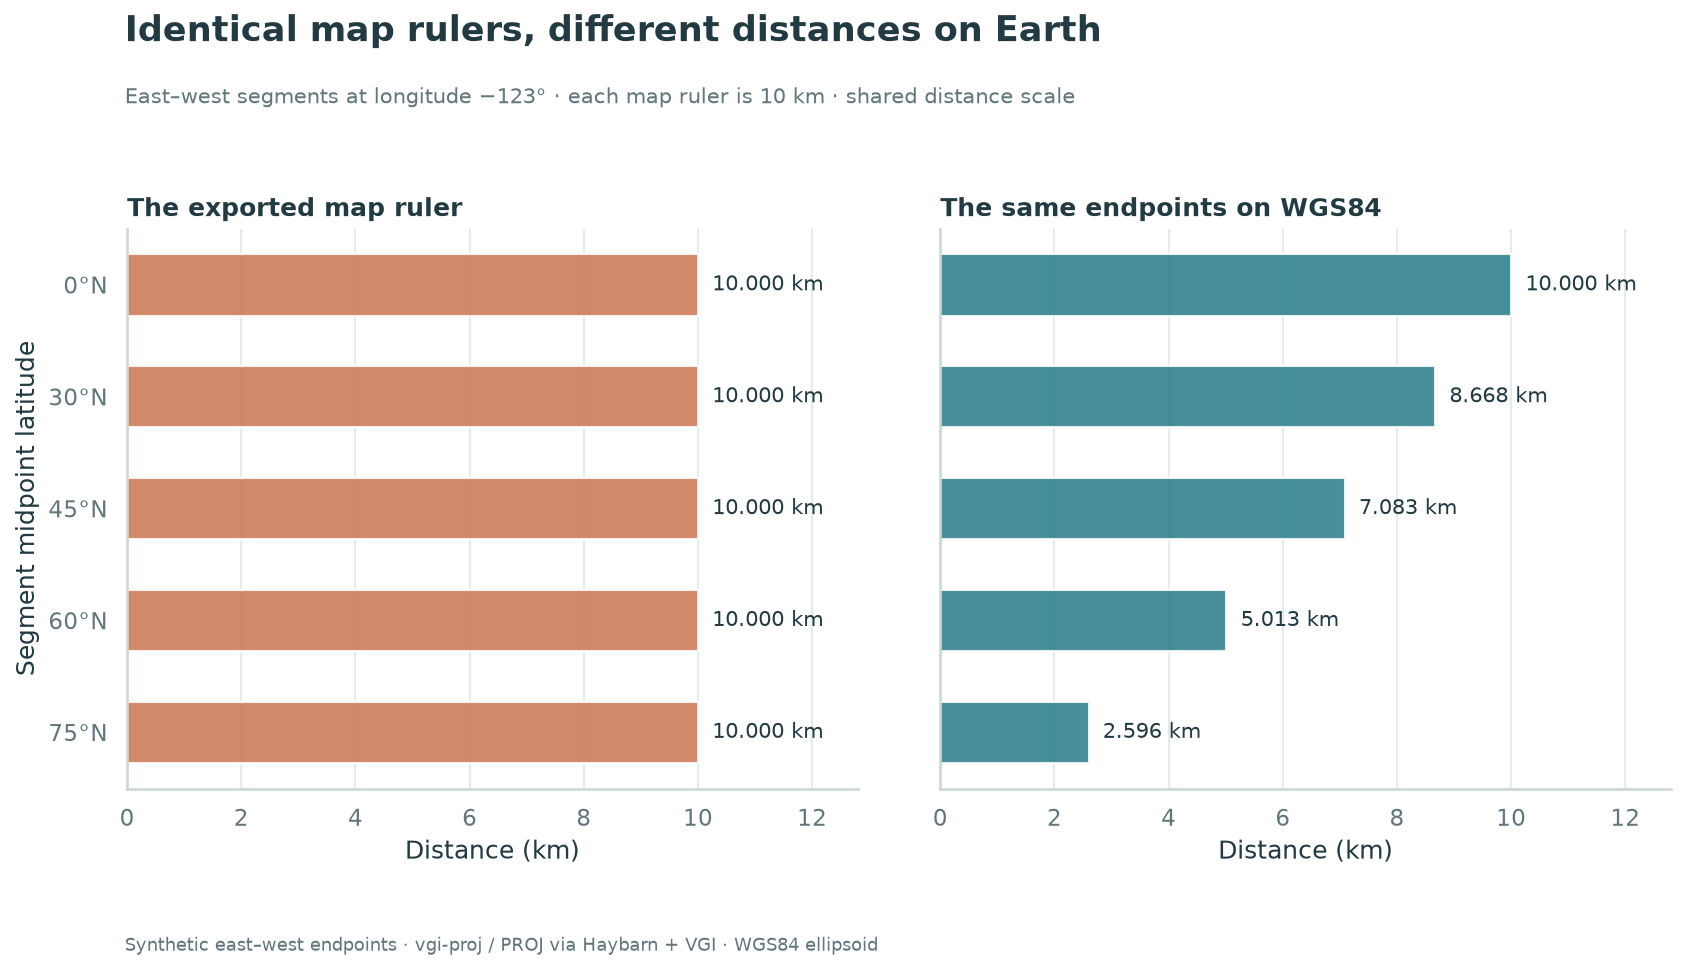

In [9]:
landmarks = distance_frame.loc[distance_frame.latitude_deg.isin([0, 30, 45, 60, 75]) | distance_frame.is_focus].copy()
positions = np.arange(len(landmarks))
fig, axes = plt.subplots(1, 2, figsize=(11.4, 6.5), sharey=True)
for ax, column, color, label in [
    (axes[0], "webmercator_m", MERCATOR, "The exported map ruler"),
    (axes[1], "geodesic_m", GEODESIC, "The same endpoints on WGS84"),
]:
    values = landmarks[column].to_numpy() / 1000
    ax.barh(positions, values, color=color, alpha=0.86, height=0.55)
    for y, length in zip(positions, values, strict=True):
        ax.text(length + MAP_LENGTH_M / 1000 * 0.025, y, f"{length:,.3f} km", va="center", fontsize=10)
    ax.set(xlabel="Distance (km)", title=label, xlim=(0, MAP_LENGTH_M / 1000 * 1.28))
    ax.xaxis.grid(True)
    ax.yaxis.grid(False)
axes[0].set_yticks(positions, [f"{x:g}°N" for x in landmarks.latitude_deg])
axes[0].set_ylabel("Segment midpoint latitude")
axes[0].invert_yaxis()
chart(
    fig,
    "Identical map rulers, different distances on Earth",
    f"East–west segments at longitude −123° · each map ruler is {MAP_LENGTH_M / 1000:g} km · shared distance scale",
)

In [10]:
focus = distance_frame.loc[distance_frame.is_focus].iloc[0]
equator = distance_frame.loc[distance_frame.latitude_deg.eq(0)].iloc[0]
prose(
    f"At **{FOCUS_LATITUDE_DEG:g}°N**, the **{MAP_LENGTH_M / 1000:g} km** map ruler spans "
    f"only **{focus.geodesic_m / 1000:.3f} km** between its WGS84 endpoints: "
    f"the map value is **{focus.map_to_ground_ratio:.4f}×** the geodesic. "
    f"At the equator the same construction gives **{equator.geodesic_m / 1000:.3f} km**. "
    "A single fixed conversion from map metres to ground metres cannot explain this latitude sweep. "
    "Next, compare the measured scale factor with a simple geometric prediction."
)

At **45°N**, the **10 km** map ruler spans only **7.083 km** between its WGS84 endpoints: the map value is **1.4118×** the geodesic. At the equator the same construction gives **10.000 km**. A single fixed conversion from map metres to ground metres cannot explain this latitude sweep. Next, compare the measured scale factor with a simple geometric prediction.

## How much does latitude explain?

On a sphere, a small east–west displacement at latitude φ has a local Mercator
scale factor **1 / cos(φ)**: the parallel's radius shrinks by cos(φ), while map
x keeps the equatorial scale. This is a prediction for comparison, not a second
geodesic engine.

[PROJ documents Web Mercator](https://proj.org/en/stable/operations/projections/webmerc.html)
as a spherical calculation using the ellipsoid's semi-major axis. Our worker
reference uses the WGS84 **ellipsoid** and a finite endpoint pair, so exact
agreement with the spherical local rule is not expected. SQL keeps the residual
visible as parts per thousand, rather than hiding it under nearly overlapping lines.

In [11]:
%%sql
CREATE OR REPLACE TABLE scale_comparison AS
SELECT latitude_deg, latitude_deg = focus_latitude_deg AS is_focus,
       webmercator_m / geodesic_m AS measured_scale,
       1.0 / COS(RADIANS(latitude_deg)) AS spherical_local_scale,
       1000 * ((1.0 / COS(RADIANS(latitude_deg))) / (webmercator_m / geodesic_m) - 1)
           AS spherical_relative_difference_per_mille
FROM distances;
SELECT latitude_deg, ROUND(measured_scale, 6) AS measured_scale,
       ROUND(spherical_local_scale, 6) AS spherical_local_scale,
       ROUND(spherical_relative_difference_per_mille, 4) AS spherical_difference_per_mille
FROM scale_comparison
WHERE latitude_deg IN (0, 30, 45, 60, 75) OR is_focus
ORDER BY latitude_deg;

,latitude_deg,measured_scale,spherical_local_scale,spherical_difference_per_mille
0,0.0,1.00000,1.00000,-0.0000
1,30.0,1.15373,1.15470,0.8378
2,45.0,1.41185,1.41421,1.6778
3,60.0,1.99497,2.00000,2.5198
4,75.0,3.85162,3.86370,3.1376


In [12]:
%%sql scale_frame <<
SELECT * FROM scale_comparison ORDER BY latitude_deg;

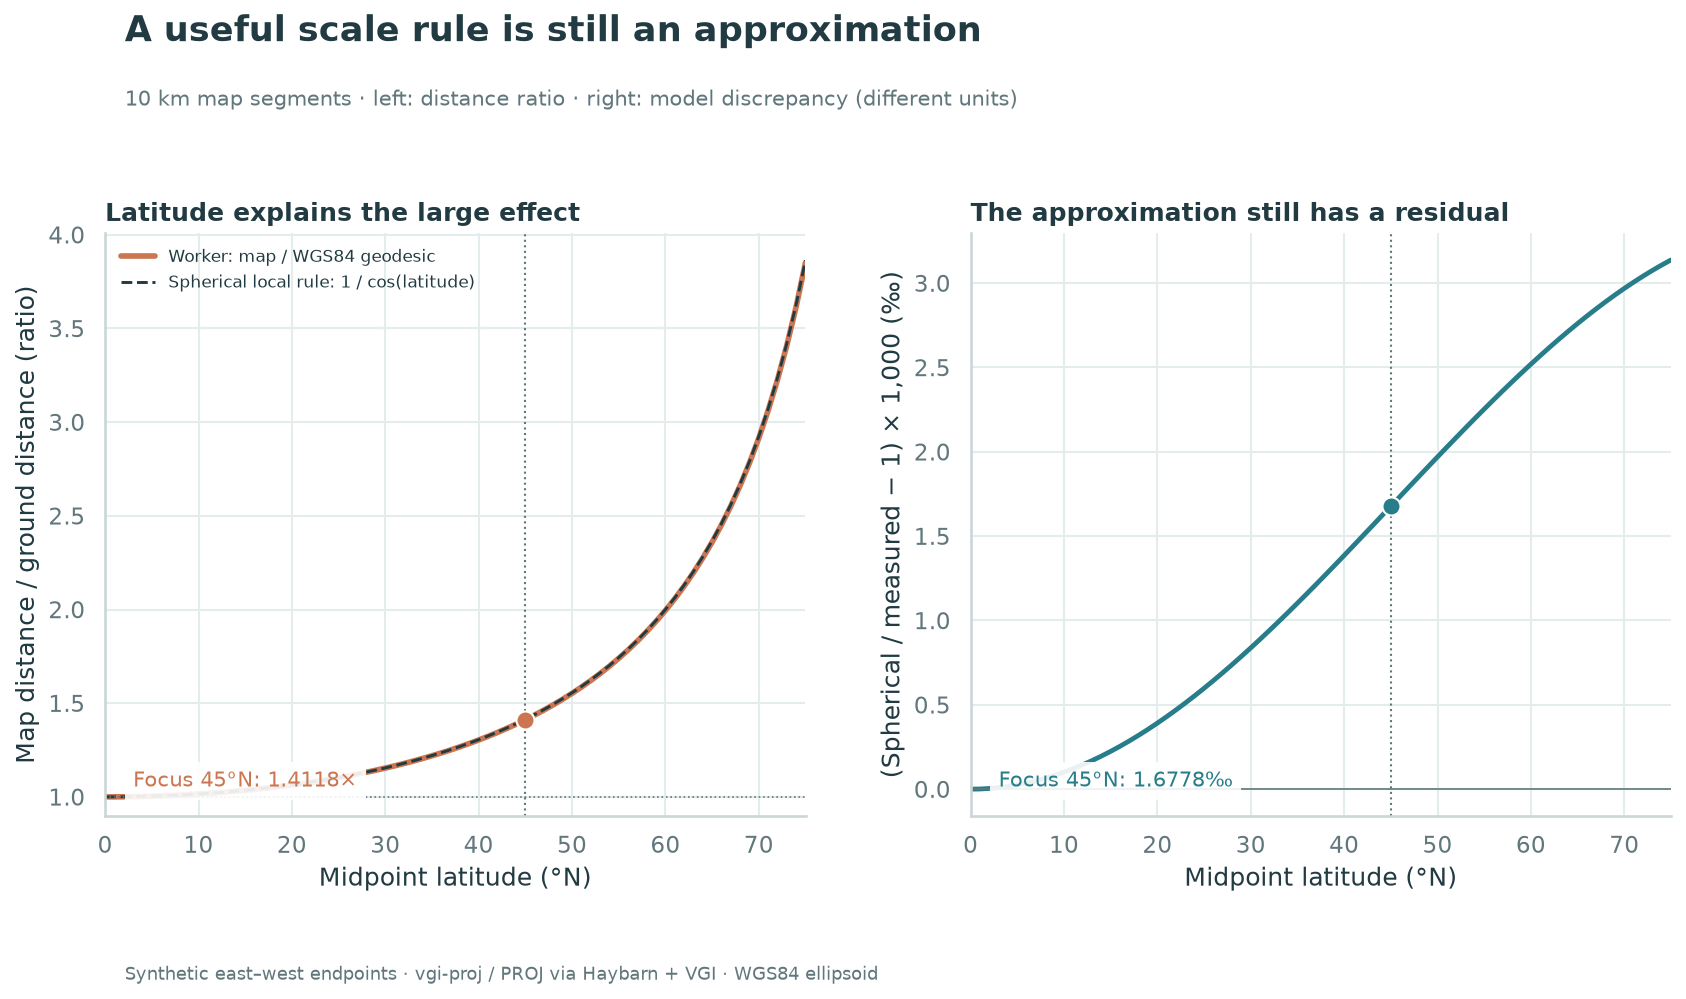

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11.4, 6.7))
axes[0].plot(
    scale_frame.latitude_deg,
    scale_frame.measured_scale,
    color=MERCATOR,
    linewidth=2.7,
    label="Worker: map / WGS84 geodesic",
)
axes[0].plot(
    scale_frame.latitude_deg,
    scale_frame.spherical_local_scale,
    color=INK,
    linewidth=1.4,
    linestyle="--",
    label="Spherical local rule: 1 / cos(latitude)",
)
axes[0].axhline(1, color=MUTED, linewidth=0.8, linestyle=":")
axes[0].set(
    xlabel="Midpoint latitude (°N)",
    ylabel="Map distance / ground distance (ratio)",
    title="Latitude explains the large effect",
    xlim=(0, 75),
    ylim=(0.9, None),
)
axes[0].legend(loc="upper left", fontsize=8.2)
axes[1].plot(
    scale_frame.latitude_deg, scale_frame.spherical_relative_difference_per_mille, color=GEODESIC, linewidth=2.3
)
axes[1].axhline(0, color=MUTED, linewidth=0.8)
axes[1].set(
    xlabel="Midpoint latitude (°N)",
    ylabel="(Spherical / measured − 1) × 1,000 (‰)",
    title="The approximation still has a residual",
    xlim=(0, 75),
)
s = scale_frame.loc[scale_frame.is_focus].iloc[0]
for ax, value, color in [
    (axes[0], s.measured_scale, MERCATOR),
    (axes[1], s.spherical_relative_difference_per_mille, GEODESIC),
]:
    ax.axvline(FOCUS_LATITUDE_DEG, color=MUTED, linewidth=1, linestyle=":")
    ax.scatter([FOCUS_LATITUDE_DEG], [value], color=color, edgecolor="white", s=75, zorder=4)
    ax.text(
        0.04,
        0.05,
        f"Focus {FOCUS_LATITUDE_DEG:g}°N: {value:.4f}" + ("×" if ax is axes[0] else "‰"),
        transform=ax.transAxes,
        color=color,
        fontsize=10,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9},
    )
chart(
    fig,
    "A useful scale rule is still an approximation",
    f"{MAP_LENGTH_M / 1000:g} km map segments · left: distance ratio · right: model discrepancy (different units)",
)

In [14]:
prose(
    f"At **{FOCUS_LATITUDE_DEG:g}°N**, the spherical rule predicts **{s.spherical_local_scale:.4f}×** "
    f"against the worker's **{s.measured_scale:.4f}×**. Its relative difference is "
    f"**{s.spherical_relative_difference_per_mille:+.4f}‰** "
    f"(**{s.spherical_relative_difference_per_mille / 10:+.4f}%**). "
    "The large latitude effect and the small approximation residual answer different questions. "
    "This controlled east–west comparison does not establish a universal correction for arbitrary routes or bearings."
)

At **45°N**, the spherical rule predicts **1.4142×** against the worker's **1.4118×**. Its relative difference is **+1.6778‰** (**+0.1678%**). The large latitude effect and the small approximation residual answer different questions. This controlled east–west comparison does not establish a universal correction for arbitrary routes or bearings.

## Can a local projected CRS preserve distance more closely?

Transform those **same geographic endpoints** to UTM. We chose longitude −123°
to stay near zone 10N's central meridian and limited the ruler to 50 km or less.
[UTM is a family of local projections](https://proj.org/en/stable/operations/projections/utm.html),
with different zones; it is not one global coordinate plane.

We subtract UTM coordinates **only when both returned EPSG identifiers agree**.
Subtracting numbers from different zones or hemispheres would have no common
coordinate reference. The signed error below is projected distance minus the
geodesic: positive is too long, negative is too short. UTM is not assumed exact.

In [15]:
%%sql
CREATE OR REPLACE TABLE utm_endpoints AS
SELECT *, proj.main.to_utm(west.lon, west.lat) AS west_utm,
          proj.main.to_utm(east.lon, east.lat) AS east_utm
FROM distances;
CREATE OR REPLACE TABLE projection_comparison AS
WITH measured AS (
    SELECT *, CASE WHEN west_utm.epsg = east_utm.epsg THEN
        SQRT(POWER(east_utm.easting - west_utm.easting, 2) +
             POWER(east_utm.northing - west_utm.northing, 2))
        ELSE NULL END AS utm_m
    FROM utm_endpoints
)
SELECT *, 100 * (webmercator_m / geodesic_m - 1) AS webmercator_error_pct,
          100 * (utm_m / geodesic_m - 1) AS utm_error_pct
FROM measured;
SELECT COUNT(*) AS pairs, COUNT(*) FILTER (WHERE utm_m IS NULL) AS unavailable_utm_distances,
       COUNT(DISTINCT west_utm.epsg) AS west_endpoint_crs_count,
       MIN(west_utm.epsg) AS west_endpoint_epsg,
       MAX(ABS(utm_error_pct)) AS largest_absolute_utm_error_pct
FROM projection_comparison;

,pairs,unavailable_utm_distances,west_endpoint_crs_count,west_endpoint_epsg,largest_absolute_utm_error_pct
0,76,0,1,32610,0.04


In [16]:
%%sql
SELECT latitude_deg, west_utm.epsg AS west_epsg, east_utm.epsg AS east_epsg,
       ROUND(geodesic_m, 3) AS geodesic_m, ROUND(webmercator_m, 3) AS webmercator_m,
       ROUND(utm_m, 3) AS utm_m, ROUND(webmercator_m - geodesic_m, 3) AS webmercator_error_m,
       ROUND(utm_m - geodesic_m, 3) AS utm_error_m
FROM projection_comparison WHERE latitude_deg = focus_latitude_deg;

,latitude_deg,west_epsg,east_epsg,geodesic_m,webmercator_m,utm_m,webmercator_error_m,utm_error_m
0,45.0,32610,32610,7082.931,10000.0,7080.099,2917.069,-2.833


In [17]:
%%sql projection_frame <<
SELECT latitude_deg, latitude_deg = focus_latitude_deg AS is_focus,
       geodesic_m, webmercator_m, utm_m, webmercator_error_pct, utm_error_pct
FROM projection_comparison ORDER BY latitude_deg;

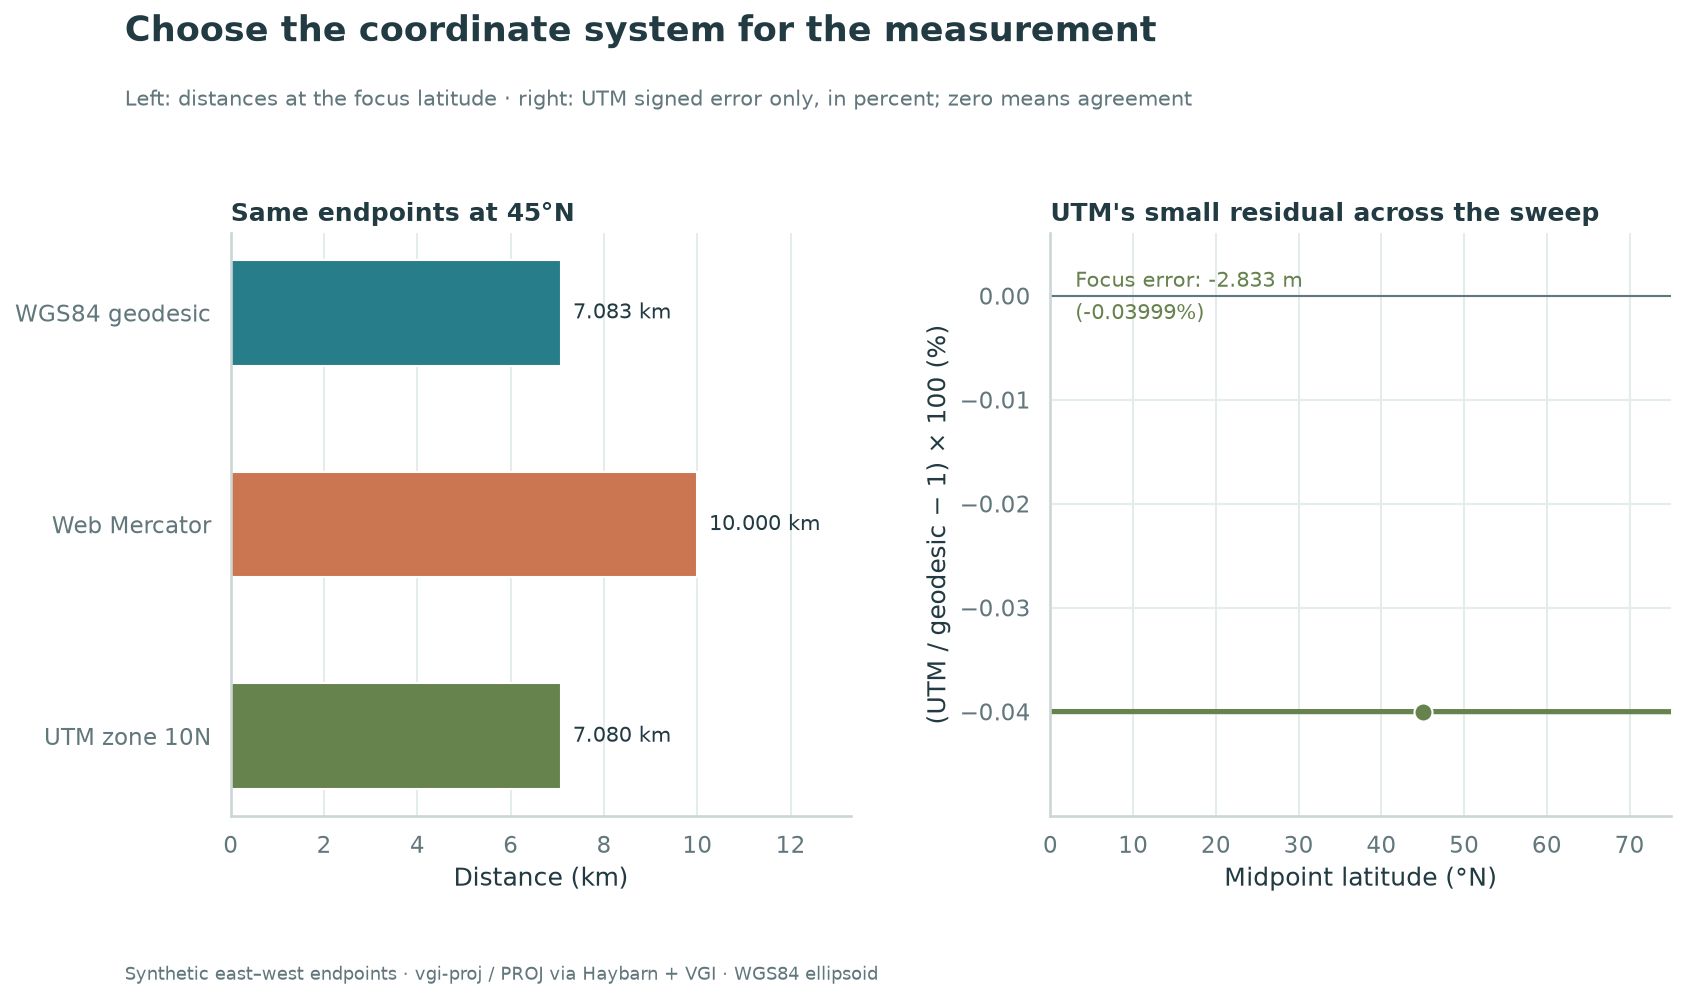

In [18]:
p = projection_frame.loc[projection_frame.is_focus].iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(11.4, 6.7))
labels = ["WGS84 geodesic", "Web Mercator", "UTM zone 10N"]
values = np.array([p.geodesic_m, p.webmercator_m, p.utm_m]) / 1000
axes[0].barh(np.arange(3), values, color=[GEODESIC, MERCATOR, UTM], height=0.5)
for y, value in enumerate(values):
    axes[0].text(value + values.max() * 0.025, y, f"{value:.3f} km", va="center", fontsize=10)
axes[0].set_yticks(np.arange(3), labels)
axes[0].invert_yaxis()
axes[0].set(xlabel="Distance (km)", xlim=(0, values.max() * 1.33), title=f"Same endpoints at {FOCUS_LATITUDE_DEG:g}°N")
axes[0].yaxis.grid(False)
axes[1].plot(projection_frame.latitude_deg, projection_frame.utm_error_pct, color=UTM, linewidth=2.5)
axes[1].axhline(0, color=MUTED, linewidth=1)
axes[1].scatter([FOCUS_LATITUDE_DEG], [p.utm_error_pct], color=UTM, edgecolor="white", s=75, zorder=4)
axes[1].set(
    xlabel="Midpoint latitude (°N)",
    ylabel="(UTM / geodesic − 1) × 100 (%)",
    title="UTM's small residual across the sweep",
    xlim=(0, 75),
    ylim=(min(projection_frame.utm_error_pct.min() * 1.25, -0.005), 0.006),
)
axes[1].text(
    0.04,
    0.95,
    f"Focus error: {p.utm_m - p.geodesic_m:+.3f} m\n({p.utm_error_pct:+.5f}%)",
    transform=axes[1].transAxes,
    va="top",
    fontsize=10,
    color=UTM,
    linespacing=1.6,
)
chart(
    fig,
    "Choose the coordinate system for the measurement",
    "Left: distances at the focus latitude · right: UTM signed error only, in percent; zero means agreement",
)

In [19]:
prose(
    f"For this pair at **{FOCUS_LATITUDE_DEG:g}°N**, Web Mercator overstates the geodesic by "
    f"**{p.webmercator_m - p.geodesic_m:,.3f} m ({p.webmercator_error_pct:+.3f}%)**. "
    f"UTM differs by **{p.utm_m - p.geodesic_m:+.3f} m ({p.utm_error_pct:+.5f}%)**. "
    "The UTM residual is small here because the segments are short and near its central meridian; "
    "this does not make UTM globally distance-preserving. For endpoint distance on the WGS84 "
    "ellipsoid, the worker's geodesic function remains the direct answer. "
    "Projection is useful when the surrounding spatial analysis needs a suitable local plane."
)

For this pair at **45°N**, Web Mercator overstates the geodesic by **2,917.069 m (+41.184%)**. UTM differs by **-2.833 m (-0.03999%)**. The UTM residual is small here because the segments are short and near its central meridian; this does not make UTM globally distance-preserving. For endpoint distance on the WGS84 ellipsoid, the worker's geodesic function remains the direct answer. Projection is useful when the surrounding spatial analysis needs a suitable local plane.

## Check the coordinate relationships

These checks compare independently composed worker paths: Web Mercator round
trips, the general `transform` against its shorthand, geodesic symmetry, and
UTM CRS compatibility. They also distinguish a valid zero distance from a NULL
input. Floating comparisons allow a one-micrometre tolerance for roundoff.
A missing measurement never becomes zero or enters a ranking.

In [20]:
%%sql validation <<
SELECT
    (SELECT COUNT(*) = COUNT(DISTINCT latitude_deg) FROM distances) AS unique_latitudes,
    (SELECT BOOL_AND(geodesic_m IS NOT NULL AND west IS NOT NULL AND east IS NOT NULL)
       FROM distances) AS complete_geodesics,
    (SELECT BOOL_AND(geodesic_m > 0 AND webmercator_m > 0) FROM distances) AS positive_lengths,
    (SELECT BOOL_AND(ABS(webmercator_m - map_length_m) < 1e-6)
       FROM distances) AS ruler_length_preserved,
    (SELECT BOOL_AND(ABS(proj.main.to_webmercator(west.lon, west.lat).x - west_x_m) < 1e-6
                    AND ABS(proj.main.to_webmercator(west.lon, west.lat).y - centre.y) < 1e-6)
       FROM distances) AS inverse_forward_round_trip,
    (SELECT BOOL_AND(ABS(proj.main.transform(midpoint_longitude_deg, latitude_deg,
                       'EPSG:4326', 'EPSG:3857').y - centre.y) < 1e-6)
       FROM distances) AS general_transform_agrees,
    (SELECT BOOL_AND(ABS(proj.main.geodesic_distance(east.lon, east.lat, west.lon, west.lat)
                       - geodesic_m) < 1e-6) FROM distances) AS geodesic_symmetry,
    (SELECT BOOL_AND(west_utm.epsg = east_utm.epsg AND utm_m IS NOT NULL)
       FROM projection_comparison) AS same_utm_crs,
    ABS(proj.main.geodesic_distance(-123.0, 45.0, -123.0, 45.0)) < 1e-6 AS zero_distance_valid,
    proj.main.geodesic_distance(NULL, 45.0, -123.0, 45.0) IS NULL AS missing_stays_null;

In [21]:
display(validation.T.rename(columns={0: "passed"}))
assert validation.notna().all().all(), "A required coordinate relationship returned no evidence."
assert validation.astype(bool).all().all(), "A coordinate relationship failed."
prose(
    f"**All {validation.shape[1]} relationship checks passed.** Table and chart labels are rounded; "
    "calculations and comparisons use full returned precision."
)

,passed
unique_latitudes,True
complete_geodesics,True
positive_lengths,True
ruler_length_preserved,True
inverse_forward_round_trip,True
general_transform_agrees,True
geodesic_symmetry,True
same_utm_crs,True
zero_distance_valid,True
missing_stays_null,True


**All 10 relationship checks passed.** Table and chart labels are rounded; calculations and comparisons use full returned precision.

## Focused experiment: move the ruler to 60°N

Change only **`FOCUS_LATITUDE_DEG = 60.0`**, restart, and run all. Keep
`MAP_LENGTH_M = 10000.0`. Predict a **shorter geodesic distance** and a **larger
Web Mercator / geodesic ratio** than at 45°N. UTM should stay close to the geodesic
for these controlled local segments. The 0–75° background sweep should not move.

Compare the focus summary and final chart: the ratio should approach two, but
the ellipsoidal result need not equal the spherical rule exactly. Compare UTM's
**signed metre error** as well as its percent error; changing the endpoint
distance changes those two quantities differently.

This isolates latitude for one short east–west ruler at a fixed longitude. It
does not test arbitrary bearings, cross-zone subtraction, long routes, terrain
or a whole map's distance accuracy. Reset **`FOCUS_LATITUDE_DEG = 45.0`** for
the default. [Save an experiment copy](README.md#one-parameter-experiment) with
the runner to preserve this executed example.

In [22]:
con.close()

---

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="210"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook guide](README.md)